# Twelve carts by hand, with support, confidence and lift and the confidence trap: what do twelve carts say?

**Week 4, Wednesday, chapter 7, the first case chapter.** Swiggy Instamart, Pune: the
cart page shows a strip of three suggested items under the cart. On Monday 7 September 2026 the
strip stopped showing a curated list and started showing the items most often found in
the same cart. Toned milk sits in 71 percent of Pune carts, so it now appears
beside nearly everything, and the strip's click-through (clicks over impressions, an
impression being one showing of one slot) fell from 6.1 percent in the three
weeks before to 3.8 percent in the three weeks after. The ask, due Friday: rank
the pairs the strip should show, explain the fall, and put a rupee value on a slot.
Illustrative case: the company is real, the situation and the data are synthetic, built for this class.

**Applies:** Support, confidence and lift, derived by counting (chapters 1 to 3,
notebooks 01 to 03); The confidence trap; lift near one (chapter 4, notebook 04); The
support floor and the watch list (chapter 6, notebook 06).

**Who needs the answer.** The category manager, who decides which products are promoted,
and the growth lead, who owns the strip's clicks and orders and must explain the fall at
Friday's review, the weekly meeting where both defend their numbers. A strip filled on the
wrong count wastes the three most-clicked spaces on the cart page.

**The questions on the way.** How often do two items turn up in the same cart? How
reliably does one bring the other? Do they turn up together more than chance would put
them there? What can twelve carts not tell us?

In [1]:
def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)
    assert ok, name
import matplotlib.pyplot as plt
plt.rcParams.update({"font.size": 12, "axes.spines.top": False, "axes.spines.right": False})
import pandas as pd
print("ready: pandas", pd.__version__)

ready: pandas 3.0.5


## What do twelve carts from the case hold?

These are twelve of the 40,000 Pune carts, printed as cards on each table. Each row is a
cart and each column an item: 1 if the cart holds it. Count by hand first, as the canteen's
orders were counted; the code below only confirms the count.

C000098 bananas, bread, coriander, eggs, onions, potatoes, toned milk
C003216 bananas, bread, curd, eggs, toned milk
C006334 bread, curd, onions, paneer, toned milk
C009452 bread, eggs, tomatoes, toned milk
C012570 chips, cold drink, eggs, onions, toned milk
C015688 chips, cold drink, coriander, toned milk
C018806 bananas, onions, potatoes, toned milk
C022633 coriander, paneer, tomatoes, toned milk
C026803 chips, coriander, onions, potatoes
C030743 bananas, cold drink, curd, tomatoes
C033861 chocolate sauce, eggs, ice cream
C036979 curd, onions


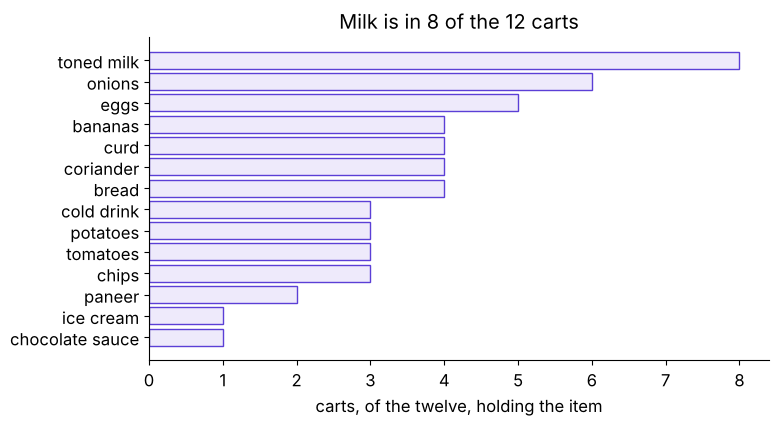

PASS twelve carts


In [2]:
twelve = pd.read_csv("../data/C2_W04_D03_twelve_rows_STUDENT.csv").set_index("cart_id")
for cart_id, row in twelve.iterrows():
    print(cart_id, ", ".join(row.index[row == 1]))
held = twelve.sum().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(held.index, held.values, color="#EEEAFB", edgecolor="#5B3FD6")
ax.set_xlabel("carts, of the twelve, holding the item")
ax.set_title("Milk is in 8 of the 12 carts")
plt.show()
check("twelve carts", len(twelve) == 12)

## How reliably does bread bring milk on the twelve carts?

Bread is in 4 carts and milk in 8.

**Predict before you run.** What is the confidence from bread to milk?

a) 0.33
b) 0.50
c) 0.75
d) 1.00

In [3]:
n = len(twelve)
bread, milk = twelve["bread"] == 1, twelve["toned milk"] == 1
both = (bread & milk).sum()
conf = both / bread.sum()
expected = n * (bread.sum() / n) * (milk.sum() / n)
lift = both / expected
print(f"bread {bread.sum()}, milk {milk.sum()}, both {both}")
print(f"support {both / n:.2f}, confidence bread to milk {conf:.2f}, milk to bread {both / milk.sum():.2f}")
print(f"expected together {expected:.2f}, seen {both}, lift {lift:.2f}")
check("every bread cart holds milk", conf == 1.0)
check("lift is 1.50 on the twelve", round(lift, 2) == 1.50)

bread 4, milk 8, both 4
support 0.33, confidence bread to milk 1.00, milk to bread 0.50
expected together 2.67, seen 4, lift 1.50
PASS every bread cart holds milk
PASS lift is 1.50 on the twelve


**What happened.** The answer is d: all four bread carts hold milk, so confidence reads
1.00. That is chapter 4's trap, met again: dal rice to chaas read
1.00 at the canteen. A hurried analyst reads 1.00 as "every bread buyer wants milk, so put
milk in the bread cart's strip". The check is the count the confidence never looked at:
milk was already in 8 of 12 carts, so chance alone puts it in about 2.67 of the four bread
carts, and lift is 4 / 2.67 = 1.50. Four carts are too few to say
more, which is chapter 6's floor; chapter 8 runs the same count on 40,000. The 2 by 2 below
is chapter 1's table, drawn for bread and milk.

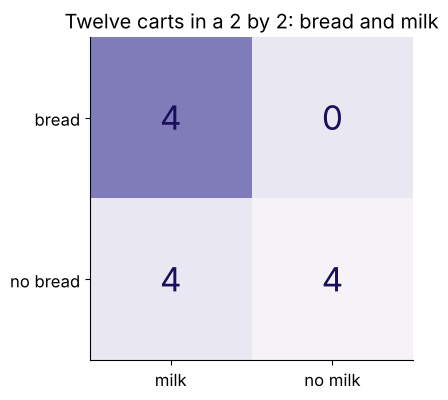

PASS the 2 by 2 adds to twelve


In [4]:
grid = [[(bread & milk).sum(), (bread & ~milk).sum()], [(milk & ~bread).sum(), (~bread & ~milk).sum()]]
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.imshow([[1, 0.25], [0.25, 0.1]], cmap="Purples", vmin=0, vmax=1.6)
for i in range(2):
    for j in range(2):
        ax.text(j, i, grid[i][j], ha="center", va="center", fontsize=24, color="#1A0F5C")
ax.set_xticks([0, 1], ["milk", "no milk"])
ax.set_yticks([0, 1], ["bread", "no bread"])
ax.set_title("Twelve carts in a 2 by 2: bread and milk")
plt.show()
check("the 2 by 2 adds to twelve", sum(map(sum, grid)) == n)

In [5]:
rows = []
for a, b in [("bread", "toned milk"), ("chips", "cold drink"), ("ice cream", "chocolate sauce")]:
    has_a, has_b = twelve[a] == 1, twelve[b] == 1
    both = (has_a & has_b).sum()
    rows.append({"pair": f"{a} + {b}", "carts_a": has_a.sum(), "carts_b": has_b.sum(), "both": both,
                 "expected": has_a.sum() * has_b.sum() / n, "support": both / n,
                 "confidence": both / has_a.sum(), "lift": both * n / (has_a.sum() * has_b.sum())})
counts = pd.DataFrame(rows).set_index("pair")
for pair in ["chips + cold drink", "ice cream + chocolate sauce"]:
    r = counts.loc[pair]
    print(f"{pair}: {r.carts_a:.0f} and {r.carts_b:.0f} carts, both {r.both:.0f}, support {r.support:.2f}, "
          f"confidence {r.confidence:.2f}, lift {r.lift:.2f}")
check("chips and cold drink: lift 2.67", round(counts.loc["chips + cold drink", "lift"], 2) == 2.67)
check("ice cream and chocolate sauce: one cart, lift 12", counts.loc["ice cream + chocolate sauce", "both"] == 1)

chips + cold drink: 3 and 3 carts, both 2, support 0.17, confidence 0.67, lift 2.67
ice cream + chocolate sauce: 1 and 1 carts, both 1, support 0.08, confidence 1.00, lift 12.00
PASS chips and cold drink: lift 2.67
PASS ice cream and chocolate sauce: one cart, lift 12


## Which pair beat chance on the twelve, and which number should nobody act on?

Chips and cold drink sit in 3 carts each and together in 2, where chance gives 0.75: lift
2.67. Ice cream and chocolate sauce share one cart, and one cart makes a lift of 12, a
number with nothing under it, which chapter 6's floor refuses. The loop above writes lift
as both x n / (A x B), which is seen over expected rearranged: for bread and milk,
4 / (12 x 4/12 x 8/12) is the same as 4 x 12 / (4 x 8), which is 1.50. The picture puts
seen beside expected for the three pairs.

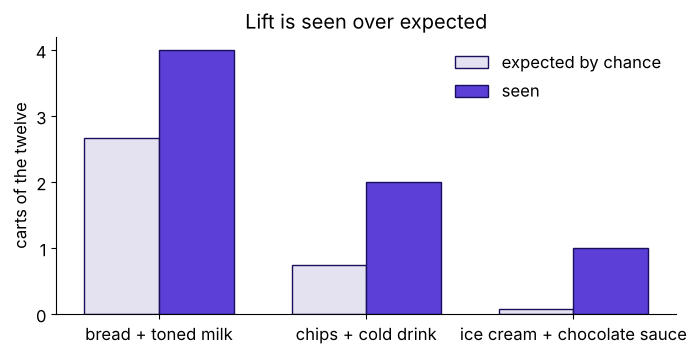

PASS every pair here was seen more often than chance


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
x = range(len(counts))
ax.bar([i - 0.18 for i in x], counts.expected, 0.36, color="#E4E1F1", edgecolor="#1A0F5C", label="expected by chance")
ax.bar([i + 0.18 for i in x], counts.both, 0.36, color="#5B3FD6", edgecolor="#1A0F5C", label="seen")
ax.set_xticks(list(x), counts.index)
ax.set_ylabel("carts of the twelve")
ax.legend(frameon=False)
ax.set_title("Lift is seen over expected")
plt.show()
check("every pair here was seen more often than chance", (counts.both > counts.expected).all())

## What did the twelve carts answer?

- **How often?** Support counts carts with both: bread and milk 4 of 12, chips and cold
  drink 2 of 12.
- **How reliably?** Confidence shrinks the world to the carts with A: bread to milk 4 of 4,
  1.00.
- **Against chance?** Lift divides seen by expected: bread and milk
  1.50, chips and cold drink 2.67, ice
  cream and chocolate sauce 12 on a single cart.
- **What can twelve carts not tell us?** Whether 1.50 is a real pull or four lucky carts.
  Chapter 8 counts all 40,000.

**In the interview.** "Support, confidence, lift: what does each answer?" The answer names
three questions: how often, how reliably, and against chance.